In [22]:
import os

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from io import BytesIO
from tqdm.notebook import tqdm
import cv2

import common

In [23]:
def read_pbtxt_to_dict(pbtxt_file):
    data_dict = {}
    with open(pbtxt_file, 'r') as file:
        item_dict = {}
        for line in file:
            line = line.strip()
            if line.startswith("item {"):
                item_dict = {}
            elif line.startswith("}"):
                data_dict[item_dict['id']] = item_dict['display_name']
            else:
                key, value = line.split(':', 1)
                item_dict[key.strip()] = value.strip().strip('"')
    return data_dict

# Replace 'your_pbtxt_file_path.pbtxt' with the path to your pbtxt file
pbtxt_file_path = 'data/label_map.pbtxt'
result_dict = read_pbtxt_to_dict(pbtxt_file_path)
print(result_dict)

{'1': 'person', '2': 'chair', '3': 'table', '4': 'armchair', '5': 'tv', '6': 'wheeled walker'}


In [24]:
ds = common.load_dataset("data/training_25k_sample_4_mask.tfrecord", common.parse_feature_masks)

In [25]:
for example in ds:
    img_string = (example['image/encoded'].numpy())
    pil_img = Image.open(BytesIO(img_string))
    img  = np.array(pil_img)
    
    img_string = (example['image/encoded_categories'].numpy())
    pil_img = Image.open(BytesIO(img_string))
    img_cat  = np.array(pil_img)
    
    height = int(example['image/height'].values)
    width = int(example['image/width'].values)    

    img_id = (example['image/source_id'].numpy())
    img_filename = (example['image/filename'].numpy()).decode('utf-8')

    bb_xmin = np.array(example['image/object/bbox/xmin'].values)
    bb_ymin = np.array(example['image/object/bbox/ymin'].values)
    bb_xmax = np.array(example['image/object/bbox/xmax'].values)
    bb_ymax = np.array(example['image/object/bbox/ymax'].values)
    classes = np.array(example['image/object/class/text'].values)
    labels = np.array(example['image/object/class/label'].values)
    break

bb_xmin = np.round(bb_xmin * width).astype(int)
bb_ymin = np.round(bb_ymin * height).astype(int)
bb_xmax = np.round(bb_xmax * width).astype(int)
bb_ymax = np.round(bb_ymax * height).astype(int)

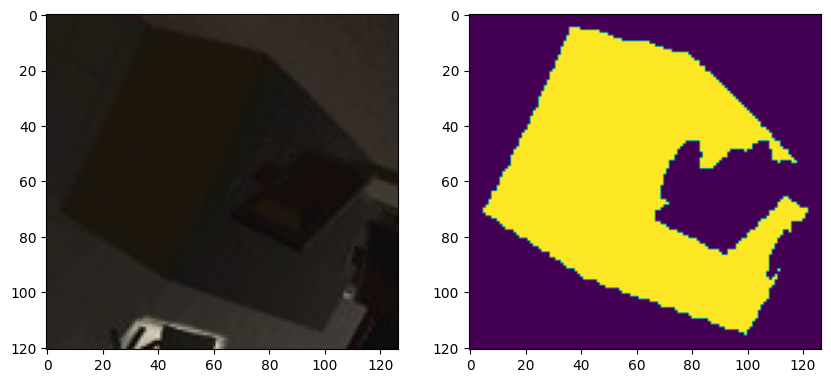

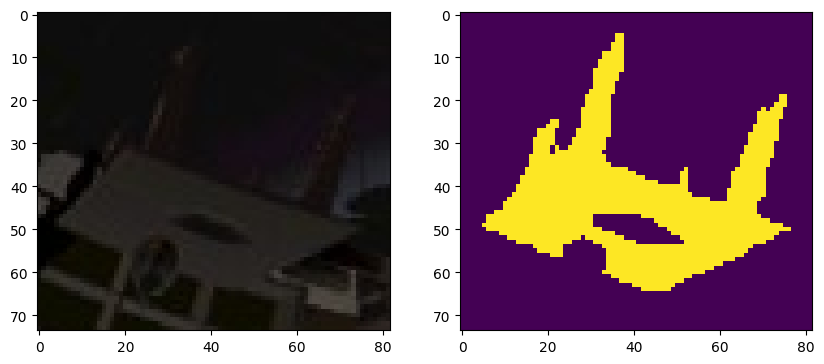

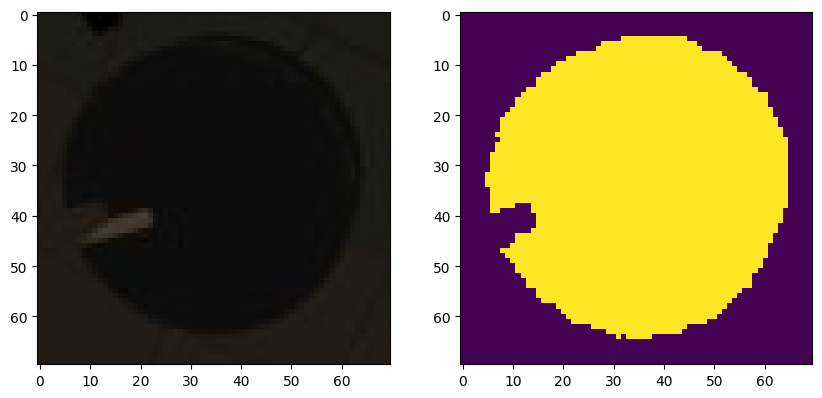

In [26]:
margin = 5

for idx in range(len(classes)):
    if classes[idx].decode() != "table":
        continue
    base_img = img[
        bb_ymin[idx] - margin: bb_ymax[idx] + margin, bb_xmin[idx] - margin: bb_xmax[idx] + margin].copy()
    mask_img = img_cat[
        bb_ymin[idx] - margin: bb_ymax[idx] + margin, bb_xmin[idx] - margin: bb_xmax[idx] + margin].copy()
    
    mask_img[mask_img != labels[idx]] = 0
    mask_img[mask_img > 0] = 1
    
    plt.figure(figsize=(10, 6))
    plt.subplot(1, 2, 1)
    plt.imshow( base_img)
    plt.subplot(1, 2, 2)
    plt.imshow(mask_img)

In [27]:
file_names = {}
for example in tqdm(ds):
    img_string = (example['image/encoded'].numpy())
    pil_img = Image.open(BytesIO(img_string))
    img  = np.array(pil_img)
    
    img_string = (example['image/encoded_categories'].numpy())
    pil_img_cat = Image.open(BytesIO(img_string))
    img_cat  = np.array(pil_img_cat)
    
    height = int(example['image/height'].values)
    width = int(example['image/width'].values)    

    img_id = (example['image/source_id'].numpy())
    img_filename = (example['image/filename'].numpy()).decode('utf-8')

    bb_xmin = np.array(example['image/object/bbox/xmin'].values)
    bb_ymin = np.array(example['image/object/bbox/ymin'].values)
    bb_xmax = np.array(example['image/object/bbox/xmax'].values)
    bb_ymax = np.array(example['image/object/bbox/ymax'].values)
    classes = np.array(example['image/object/class/text'].values)
    labels = np.array(example['image/object/class/label'].values)

    bb_xmin = np.round(bb_xmin * width).astype(int)
    bb_ymin = np.round(bb_ymin * height).astype(int)
    bb_xmax = np.round(bb_xmax * width).astype(int)
    bb_ymax = np.round(bb_ymax * height).astype(int)

    margin = 5

    count = 0
    tmp_names = []
    for idx in range(len(classes)):
        if classes[idx].decode() != "table":
            continue
        base_img = img[
            bb_ymin[idx] - margin: bb_ymax[idx] + margin, bb_xmin[idx] - margin: bb_xmax[idx] + margin].copy()
        mask_img = img_cat[
            bb_ymin[idx] - margin: bb_ymax[idx] + margin, bb_xmin[idx] - margin: bb_xmax[idx] + margin].copy()
        
        mask_img[mask_img != labels[idx]] = 0
        mask_img[mask_img > 0] = 1

        cv2.imwrite(f"theodore_unet/imgs/{img_filename.replace('.jpg', '')}_{count}.jpg", cv2.cvtColor(base_img, cv2.COLOR_RGB2BGR))
        cv2.imwrite(f"theodore_unet/masks/{img_filename.replace('.jpg', '')}_{count}.png", cv2.cvtColor(mask_img * 255, cv2.COLOR_RGB2BGR))
        tmp_names.append(f"{img_filename.replace('.jpg', '')}_{count}")
        count += 1
    file_names[img_filename.replace('.jpg', '')] = tmp_names


0it [00:00, ?it/s]

In [28]:
len(file_names)

25001

In [29]:
total_len = 0
for v in file_names.values():
    total_len += len(v)
total_len

51551

In [30]:
RANDOM_SEED = 42
TRAIN_PR = 0.9

In [31]:
filenames_keys = np.array(list(file_names.keys()))

train_n = int(filenames_keys.shape[0] * TRAIN_PR)

idxs = np.arange(filenames_keys.shape[0])
np.random.seed(RANDOM_SEED)
np.random.shuffle(idxs)

train_names = np.concatenate([file_names[k] for k in filenames_keys[idxs[:train_n]] if len(file_names[k]) > 0])
val_names = np.concatenate([file_names[k] for k in filenames_keys[idxs[train_n:]] if len(file_names[k]) > 0])

np.savetxt("theodore_unet/train.txt", train_names, "%s")
np.savetxt("theodore_unet/val.txt", val_names, "%s")

train_names.shape[0], val_names.shape[0]

(46417, 5134)